In [1]:
!pip list | grep torch

torch                                 2.14.1+cpu
torchao                               0.10.0
torchaudio                            2.11.0+cpu
torchcodec                            0.17.0+cpu
torchdata                             0.11.0
torchsummary                          1.5.1
torchtune                             0.6.1
torchvision                           0.29.1+cpu


In [2]:
import torch

*   https://pytorch.org/blog/quantization-in-practice/
*   https://pytorch.org/docs/stable/quantization.html
*   https://pytorch.org/docs/stable/quantization-support.html

### Mapping function and Quantization Parameters

In [3]:
# r - float tensor, r' - int tensor
# S [scaling factor] = (beta - alpha) / (beta_q - alpha_q)
# Z [zero point] =  -(alpha / S - alpha_q)

def quantize(float_tensor, scale, z):
  # Q(r) = round(r/S + Z)
  return torch.round(float_tensor / scale + z)

def dequantize(int_tensor, scale, z):
  # r' = (Q(r) - Z) * S
  return (int_tensor - z) * scale

In [4]:
from torch.ao.quantization.observer import MinMaxObserver, MovingAverageMinMaxObserver, HistogramObserver

C, L = 3, 4
normal = torch.distributions.normal.Normal(0,1)
inputs = normal.sample((C, L))
print(inputs)

tensor([[ 0.0724, -0.8015,  0.3346,  0.1515],
        [-0.6761,  0.4427, -0.6255, -1.9224],
        [ 0.2198, -0.7747,  0.6237, -0.8433]])


In [5]:
observers = [MinMaxObserver(), MovingAverageMinMaxObserver(), HistogramObserver()]
for obs in observers:
  obs(inputs)
  print(obs.__class__.__name__, obs.calculate_qparams())

MinMaxObserver (tensor([0.0100]), tensor([193], dtype=torch.int32))
MovingAverageMinMaxObserver (tensor([0.0100]), tensor([193], dtype=torch.int32))
HistogramObserver (tensor([0.0100]), tensor([193], dtype=torch.int32))


In [6]:
scale, z = observers[0].calculate_qparams()
reconstruction_error = torch.abs(dequantize(quantize(inputs, scale, z), scale, z) - inputs)
reconstruction_error

tensor([[0.0025, 0.0028, 0.0049, 0.0017],
        [0.0029, 0.0034, 0.0035, 0.0046],
        [0.0002, 0.0041, 0.0046, 0.0046]])

### Affine and Symmetric Quantization Schemes

In [7]:
import numpy as np
import matplotlib.pyplot as plt


def get_symmetric_range(x):
  beta = torch.max(x.max(), x.min().abs())
  return -beta.item(), beta.item()

def get_affine_range(x):
  return x.min().item(), x.max().item()

def plot(plt, data, scheme):
  boundaries = get_affine_range(data) if scheme == 'affine' else get_symmetric_range(data)
  a, _, _ = plt.hist(data, density=True, bins=100)
  ymin, ymax = np.quantile(a[a>0], [0.25, 0.95])
  plt.vlines(x=boundaries, ls='--', colors='purple', ymin=ymin, ymax=ymax)

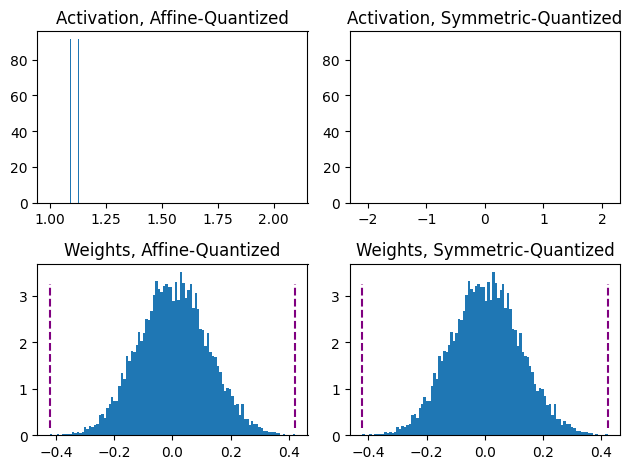

In [8]:
act =  torch.distributions.pareto.Pareto(1, 10).sample((1, 1024))
weights = torch.distributions.normal.Normal(0, 0.12).sample((3, 64, 7, 7)).flatten()

fig, axs = plt.subplots(2,2)
plot(axs[0, 0], act, 'affine')
axs[0, 0].set_title("Activation, Affine-Quantized")

plot(axs[0, 1], act, 'symmetric')
axs[0, 1].set_title("Activation, Symmetric-Quantized")

plot(axs[1, 0], weights, 'affine')
axs[1, 0].set_title("Weights, Affine-Quantized")

plot(axs[1, 1], weights, 'symmetric')
axs[1, 1].set_title("Weights, Symmetric-Quantized")

fig.tight_layout()
plt.show()

In [9]:
for qscheme in [torch.per_tensor_affine, torch.per_tensor_symmetric]:
  obs = MovingAverageMinMaxObserver(qscheme=qscheme)
  obs(inputs)
  print(f"Qscheme: {qscheme} | {obs.calculate_qparams()}")

Qscheme: torch.per_tensor_affine | (tensor([0.0100]), tensor([193], dtype=torch.int32))
Qscheme: torch.per_tensor_symmetric | (tensor([0.0151]), tensor([128]))


### Per-Tensor and Per-Channel Quantization Schemes

In [10]:
from torch.ao.quantization.observer import MovingAveragePerChannelMinMaxObserver

obs = MovingAveragePerChannelMinMaxObserver(ch_axis = 0)  # calculate qparams for all `C` channels separately
obs(inputs)
print(obs.calculate_qparams())

(tensor([0.0045, 0.0093, 0.0058]), tensor([180, 207, 147], dtype=torch.int32))


For weights quantization, symmetric-per-channel quantization provides better accuracies; per-tensor quantization performs poorly, possibly due to high variance in conv weights across channels from batchnorm folding.
[https://arxiv.org/abs/2004.09602]

https://github.com/pytorch/pytorch/blob/748d9d24940cd17938df963456c90fa1a13f3932/torch/ao/quantization/observer.py#L258

### Backend Engine

In [11]:
backend = 'fbgemm' #'fbgemm' if x86 else 'qnnpack' intel - oneDNN
qconfig = torch.ao.quantization.get_default_qconfig(backend)
torch.backends.quantized.engine = backend

GPUs - via TensorRT and cuDNN
https://pytorch.org/docs/stable/quantization.html#note-for-native-cpu-backends

### QConfig

In [12]:
my_qconfig = torch.ao.quantization.QConfig(
  activation=MovingAverageMinMaxObserver.with_args(qscheme=torch.per_tensor_affine),
  weight=MovingAveragePerChannelMinMaxObserver.with_args(qscheme=torch.qint8))

my_qconfig

QConfig(activation=functools.partial(<class 'torch.ao.quantization.observer.MovingAverageMinMaxObserver'>, qscheme=torch.per_tensor_affine){}, weight=functools.partial(<class 'torch.ao.quantization.observer.MovingAveragePerChannelMinMaxObserver'>, qscheme=torch.qint8){})

### Eager Mode v/s FX Graph Mode

*    Eager Mode Quantization is a beta feature. User needs to do fusion and specify where quantization and dequantization happens manually, also it only supports modules and not functionals.
*    FX Graph Mode Quantization is a new automated quantization framework in PyTorch, and currently it’s a prototype feature. It improves upon Eager Mode Quantization by adding support for functionals and automating the quantization process, although people might need to refactor the model to make the model compatible with FX Graph Mode Quantization (symbolically traceable with torch.fx)






FX Graph Mode automatically fuses eligible modules, inserts Quant/DeQuant stubs, calibrates the model and returns a quantized module - all in two method calls - but only for networks that are symbolic traceable. The examples below contain the calls using Eager Mode and FX Graph Mode for comparison.
https://pytorch.org/docs/stable/fx.html#torch.fx.symbolic_trace

In [13]:
def f(a, b):
    if b == True:
        return a
    else:
        return a * 2

In [41]:
f = torch.fx.symbolic_trace(f, concrete_args={'b': False})
assert f(3, True) == 6

AssertionError: Expected FunctionType, got <class 'torch.Tensor'>

https://pytorch.org/docs/stable/fx.html

### Post-Training Dynamic/Weight-only Quantization

Here the model’s weights are pre-quantized; the activations are quantized on-the-fly (“dynamic”) during inference. The simplest of all approaches, it has a one line API call in torch.quantization.quantize_dynamic. Currently only Linear and Recurrent (LSTM, GRU, RNN) layers are supported for dynamic quantization



*   Can result in higher accuracies since the clipping range is exactly calibrated for each input
*   Calibrating and quantizing the activations at each layer during runtime can add to the compute overhead



In [16]:
from torch import nn

# toy model
m = nn.Sequential(
  nn.Conv2d(2, 64, (8,)),
  nn.ReLU(),
  nn.Linear(16, 10),
  nn.LSTM(10, 10))

m.eval()

Sequential(
  (0): Conv2d(2, 64, kernel_size=(8,), stride=(1, 1))
  (1): ReLU()
  (2): Linear(in_features=16, out_features=10, bias=True)
  (3): LSTM(10, 10)
)

In [17]:
## EAGER MODE
from torch.ao.quantization import quantize_dynamic

model_quantized = quantize_dynamic(
    model=m, qconfig_spec={nn.LSTM, nn.Linear}, dtype=torch.qint8, inplace=False
)

/tmp/ipykernel_1337/2181302342.py:4: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_quantized = quantize_dynamic(
/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8,

In [18]:
## FX MODE
from torch.ao.quantization import quantize_fx

example_inputs = (torch.randn(1, 3, 224, 224),)
qconfig_dict = {"": torch.ao.quantization.default_dynamic_qconfig}  # An empty key denotes the default applied to all modules
model_prepared = quantize_fx.prepare_fx(m, qconfig_dict, example_inputs)
model_quantized = quantize_fx.convert_fx(model_prepared)

/tmp/ipykernel_1337/15622409.py:6: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_prepared = quantize_fx.prepare_fx(m, qconfig_dict, example_inputs)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/quantize_fx.py:146: FutureWarning: Passing a QConfig dictionary to prepare is deprecated and will not be supported in a future version. Please pass in a QCon

In [19]:
torch.ao.quantization.default_dynamic_qconfig

QConfig(activation=functools.partial(<class 'torch.ao.quantization.observer.PlaceholderObserver'>, dtype=torch.quint8, quant_min=0, quant_max=255, is_dynamic=True){}, weight=functools.partial(<class 'torch.ao.quantization.observer.MinMaxObserver'>, dtype=torch.qint8, qscheme=torch.per_tensor_symmetric){})

### Post-Training Static Quantization (PTQ)

PTQ also pre-quantizes model weights but instead of calibrating activations on-the-fly, the clipping range is pre-calibrated and fixed (“static”) using validation data. Activations stay in quantized precision between operations during inference. About 100 mini-batches of representative data are sufficient to calibrate the observers

*   Static quantization has faster inference than dynamic quantization because it eliminates the float<->int conversion costs between layers
*   Static quantized models may need regular re-calibration to stay robust against distribution-drift



In [20]:
# Static quantization of a model consists of the following steps:

#     Fuse modules
#     Insert Quant/DeQuant Stubs
#     Prepare the fused module (insert observers before and after layers)
#     Calibrate the prepared module (pass it representative data)
#     Convert the calibrated module (replace with quantized version)

import torch
from torch import nn
import copy

backend = "fbgemm"  # running on a x86 CPU. Use "qnnpack" if running on ARM.

model = nn.Sequential(
     nn.Conv2d(2, 64, 3),
     nn.ReLU(),
     nn.Conv2d(64, 128, 3),
     nn.ReLU()
)

In [21]:
## EAGER MODE
m = copy.deepcopy(model)
m.eval()

"""Fuse
- Inplace fusion replaces the first module in the sequence with the fused module, and the rest with identity modules
"""
torch.ao.quantization.fuse_modules(m, ['0','1'], inplace=True) # fuse first Conv-ReLU pair
torch.ao.quantization.fuse_modules(m, ['2','3'], inplace=True) # fuse second Conv-ReLU pair

"""Insert stubs"""
m = nn.Sequential(torch.ao.quantization.QuantStub(),
                  *m,
                  torch.ao.quantization.DeQuantStub())

"""Prepare"""
m.qconfig = torch.ao.quantization.get_default_qconfig(backend)
torch.ao.quantization.prepare(m, inplace=True)

"""Calibrate
- This example uses random data for convenience. Use representative (validation) data instead.
"""
with torch.inference_mode():
  for _ in range(10):
    x = torch.rand(1, 2, 28, 28)
    m(x)

"""Convert"""
torch.ao.quantization.convert(m, inplace=True)

"""Check"""
print(m[1].weight().element_size()) # 1 byte instead of 4 bytes for FP32

/tmp/ipykernel_1337/213743822.py:18: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  torch.ao.quantization.prepare(m, inplace=True)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTo

1


In [22]:
m[1].weight()

tensor([[[[ 0.0369,  0.0905,  0.0295],
          [ 0.1606,  0.0942,  0.0166],
          [ 0.0055,  0.0240, -0.1809]],

         [[-0.2123, -0.1311, -0.2215],
          [ 0.2345, -0.1348,  0.2234],
          [ 0.0277, -0.1699, -0.0314]]],


        [[[-0.0680, -0.0232,  0.1211],
          [ 0.1078, -0.0431, -0.1244],
          [-0.0979,  0.1759, -0.1543]],

         [[-0.2124,  0.0315, -0.1062],
          [-0.1195, -0.0365,  0.0581],
          [ 0.1311,  0.1361,  0.1526]]],


        [[[ 0.0963, -0.1138, -0.0280],
          [ 0.1996,  0.0158, -0.0280],
          [-0.1680,  0.2206, -0.1610]],

         [[ 0.1208,  0.1768, -0.0228],
          [ 0.0858, -0.2206, -0.0455],
          [ 0.1785,  0.1926, -0.2223]]],


        ...,


        [[[ 0.1031, -0.0857,  0.1079],
          [-0.0714,  0.0952,  0.0762],
          [ 0.1158,  0.0968, -0.0159]],

         [[ 0.0571, -0.1967,  0.1349],
          [ 0.0317,  0.2015,  0.0016],
          [ 0.1539, -0.0190, -0.0793]]],


        [[[-0.0306,  0.04

In [23]:
## FX GRAPH
from torch.ao.quantization import quantize_fx

m = copy.deepcopy(model)
m.eval()
qconfig_dict = {"": torch.ao.quantization.get_default_qconfig(backend)}

# Prepare
example_inputs = (torch.randn(1, 3, 224, 224),)
model_prepared = quantize_fx.prepare_fx(m, qconfig_dict, example_inputs)

# Calibrate - Use representative (validation) data.
with torch.inference_mode():
  for _ in range(10):
    x = torch.rand(1, 2, 28, 28)
    model_prepared(x)

# quantize
model_quantized = quantize_fx.convert_fx(model_prepared)

/tmp/ipykernel_1337/750729956.py:10: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_prepared = quantize_fx.prepare_fx(m, qconfig_dict, example_inputs)
/tmp/ipykernel_1337/750729956.py:19: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao

### SENSITIVITY ANALYSIS

In [24]:
# ONE-AT-A-TIME SENSITIVITY ANALYSIS

for quantized_layer, _ in model.named_modules():
  print("Only quantizing layer: ", quantized_layer)

  # The module_name key allows module-specific qconfigs.
  qconfig_dict = {"": None,
  "module_name":[(quantized_layer, torch.quantization.get_default_qconfig(backend))]}

  example_inputs = (torch.randn(1, 3, 224, 224),)
  model_prepared = quantize_fx.prepare_fx(model, qconfig_dict, example_inputs)
  # calibrate
  model_quantized = quantize_fx.convert_fx(model_prepared)
  # evaluate(model)

Only quantizing layer:  
Only quantizing layer:  0
Only quantizing layer:  1
Only quantizing layer:  2
Only quantizing layer:  3


/tmp/ipykernel_1337/1147990886.py:11: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_prepared = quantize_fx.prepare_fx(model, qconfig_dict, example_inputs)
/tmp/ipykernel_1337/1147990886.py:13: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, to

 Numeric Suite - https://pytorch.org/tutorials/prototype/numeric_suite_tutorial.html

In [25]:
import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets
import torchvision.transforms as transforms
import os
import torch.ao.quantization
import torch.ao.ns._numeric_suite as ns
from torch.ao.quantization import (
    default_eval_fn,
    default_qconfig,
    quantize,
)

In [26]:
float_model = torchvision.models.quantization.resnet18(pretrained=True, quantize=False)
float_model.to('cpu')
float_model.eval()
float_model.fuse_model()
float_model.qconfig = torch.quantization.default_qconfig
img_data = (torch.rand(2, 3, 10, 10, dtype=torch.float), torch.randint(0, 1, (2,), dtype=torch.long))
qmodel = quantize(float_model, default_eval_fn, [[img_data]], inplace=False)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 121MB/s]
/tmp/ipykernel_1337/409614095.py:7: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  qmodel = quantize(float_model, default_eval_fn, [[img_data]], inplace=False)


In [27]:
def compute_error(x, y):
    Ps = torch.norm(x)
    Pn = torch.norm(x - y)
    return 20 * torch.log10(Ps/Pn)

wt_compare_dict = ns.compare_weights(float_model.state_dict(), qmodel.state_dict())
for key in wt_compare_dict:
    print(key, compute_error(wt_compare_dict[key]['float'], wt_compare_dict[key]['quantized'].dequantize()))

print("---")

act_compare_dict = ns.compare_model_outputs(float_model, qmodel, img_data[0])
for key in act_compare_dict:
    print(key, compute_error(act_compare_dict[key]['float'][0], act_compare_dict[key]['quantized'][0].dequantize()))


conv1.weight tensor(31.6638)
layer1.0.conv1.weight tensor(30.6450)
layer1.0.conv2.weight tensor(31.1528)
layer1.1.conv1.weight tensor(32.1438)
layer1.1.conv2.weight tensor(31.2477)
layer2.0.conv1.weight tensor(30.9890)
layer2.0.conv2.weight tensor(28.8233)
layer2.0.downsample.0.weight tensor(31.5558)
layer2.1.conv1.weight tensor(30.7668)
layer2.1.conv2.weight tensor(28.4516)
layer3.0.conv1.weight tensor(30.9247)
layer3.0.conv2.weight tensor(26.6841)
layer3.0.downsample.0.weight tensor(28.7825)
layer3.1.conv1.weight tensor(28.9707)
layer3.1.conv2.weight tensor(25.6784)
layer4.0.conv1.weight tensor(26.8495)
layer4.0.conv2.weight tensor(25.8394)
layer4.0.downsample.0.weight tensor(28.6355)
layer4.1.conv1.weight tensor(26.8758)
layer4.1.conv2.weight tensor(28.4319)
fc._packed_params._packed_params tensor(32.6505)
---
conv1.stats tensor(37.1471, grad_fn=<MulBackward0>)
layer1.0.conv1.stats tensor(29.8983, grad_fn=<MulBackward0>)
layer1.0.conv2.stats tensor(29.1695, grad_fn=<MulBackward0>)
l

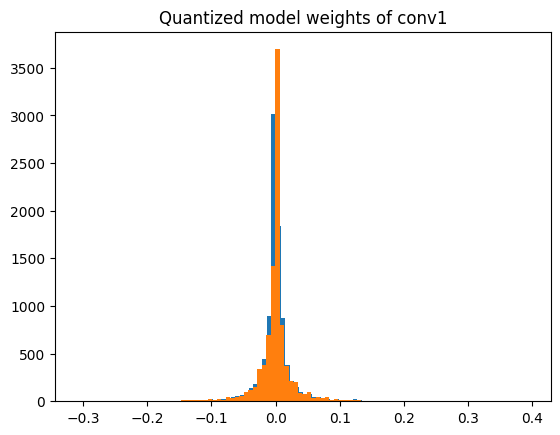

In [28]:
import matplotlib.pyplot as plt

f = wt_compare_dict['conv1.weight']['float'].flatten()
plt.hist(f, bins = 100)

q = wt_compare_dict['conv1.weight']['quantized'].flatten().dequantize()
plt.hist(q, bins = 100)
plt.title("Quantized model weights of conv1")
plt.show()

### RECOMMENDATIONS FOR YOUR WORKFLOW

![](https://drive.google.com/uc?export=view&id=1ij7GElwiKFNmJ221aKpkDRwMj5i-2DLh)



*   Large (10M+ parameters) models are more robust to quantization error
*   Quantizing a model from a FP32 checkpoint provides better accuracy than training an INT8 model from scratch
*   Dynamic Quantization is an easy first step, especially if your model has many Linear or Recurrent layers
*   Use symmetric-per-channel quantization with MinMax observers for quantizing weights. Use affine-per-tensor quantization with MovingAverageMinMax observers for quantizing activations
*   Use metrics like SQNR to identify which layers are most suscpetible to quantization error. Turn off quantization on these layers

Eager mode https://pytorch.org/docs/stable/quantization.html#eager-mode-quantization



*   https://pytorch.org/docs/stable/quantization.html#post-training-dynamic-quantization
*   https://pytorch.org/docs/stable/quantization.html#post-training-static-quantization


FX Graph https://pytorch.org/docs/stable/quantization.html#prototype-fx-graph-mode-quantization



*   https://pytorch.org/tutorials/prototype/fx_graph_mode_ptq_static.html
*   https://pytorch.org/tutorials/prototype/fx_graph_mode_ptq_dynamic.html





## New forkflow with torchao



In [29]:
!pip install torchao

In [30]:
import copy
import torch

class ToyLinearModel(torch.nn.Module):
    def __init__(self, m: int, n: int, k: int):
        super().__init__()
        self.linear1 = torch.nn.Linear(m, n, bias=False)
        self.linear2 = torch.nn.Linear(n, k, bias=False)

    def forward(self, x):
        x = self.linear1(x)
        x = self.linear2(x)
        return x

model = ToyLinearModel(1024, 1024, 1024).eval()

# Optional: compile model for faster inference and generation
model = torch.compile(model, mode="max-autotune", fullgraph=True)
model_f32 = copy.deepcopy(model)


In [31]:
from torchao.quantization import Int4DynamicActivationInt4WeightConfig, quantize_
quantize_(model, Int4DynamicActivationInt4WeightConfig())

In [32]:
from torchao.utils import (
    benchmark_model,
    unwrap_tensor_subclass,
)

num_runs = 100
torch._dynamo.reset()
example_inputs = (torch.randn(1, 1024, dtype=torch.float32),)
f32_time = benchmark_model(model_f32, num_runs, example_inputs)
int4_time = benchmark_model(model, num_runs, example_inputs)

print("f32 mean time: %0.3f ms" % f32_time)
print("int4 mean time: %0.3f ms" % int4_time)
print("speedup: %0.1fx" % (f32_time / int4_time))

/usr/local/lib/python3.13/dist-packages/torch/_functorch/_aot_autograd/autograd_cache.py:707: UserWarning: LinearActivationQuantizedTensor does not implement _stable_hash_for_caching. For PT2-compatible tensor subclasses, it is recommended to implement _stable_hash_for_caching(self) -> str for stable AOT autograd caching.
  warn_once(


f32 mean time: 0.163 ms
int4 mean time: 0.225 ms
speedup: 0.7x


In [33]:
import os
torch.save(model, "/tmp/int4_model.pt")
torch.save(model_f32, "/tmp/f32_model.pt")
int4_model_size_mb = os.path.getsize("/tmp/int4_model.pt") / 1024 / 1024
f32_model_size_mb = os.path.getsize("/tmp/f32_model.pt") / 1024 / 1024

print("int4 model size: %.2f MB" % int4_model_size_mb)

print("f32 model size: %.2f MB" % f32_model_size_mb)


int4 model size: 1.01 MB
f32 model size: 8.00 MB


### Neural Network Compression Framework (NNCF)

In [34]:
!git clone https://github.com/openvinotoolkit/nncf

Cloning into 'nncf'...
remote: Enumerating objects: 103705, done.
remote: Counting objects: 100% (833/833), done.
remote: Compressing objects: 100% (426/426), done.
remote: Total 103705 (delta 606), reused 414 (delta 405), pack-reused 102872 (from 3)
Receiving objects: 100% (103705/103705), 72.79 MiB | 18.33 MiB/s, done.
Resolving deltas: 100% (70041/70041), done.


In [35]:
# %%capture
%cd nncf
!pip install .[torch]
%cd /content

/content/nncf
Processing ./.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 23.4 MB/s  0:00:00
  Created wheel for nncf: filename=nncf-3.5.0.dev0+2dec7db5b-py3-none-any.whl size=803936 sha256=2d01f1e15b8e1393b63a305c29d4764e3bbb4c3302f2347cbb88b85134802d66
  Stored in directory: /tmp/pip-ephem-wheel-cache-3hkaq3zq/wheels/6d/e0/88/fc57195154b6b185a52dc73cff95dc1de3abc6b98b88029e3e
Successfully built nncf
  Attempting uninstall: networkx
    Found existing installation: networkx 3.7
    Uninstalling networkx-3.7:
      Successfully uninstalled networkx-3.7
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [nncf]
/content


In [36]:
import torch
import nncf.torch  # Important - must be imported before any other external package that depends on torch

https://github.com/openvinotoolkit/nncf/tree/develop
https://github.com/openvinotoolkit/nncf/blob/develop/docs/compression_algorithms/Quantization.md
https://github.com/openvinotoolkit/nncf/blob/develop/examples/torch/classification/configs/quantization/inception_v3_imagenet_int8.json

https://dev-discuss.pytorch.org/t/torch-ao-quantization-migration-plan/2810
https://docs.pytorch.org/ao/stable

---

# ONNX and TensorRT

## 1. Overview

**ONNX (Open Neural Network Exchange)** is an interoperable format for representing neural network graphs, weights and input/output information. A PyTorch model can be exported to an `.onnx` file and deployed in different inference frameworks.

**ONNX Runtime** executes ONNX models using CPU, CUDA and other execution providers. It also provides post-training quantization tools.

**NVIDIA TensorRT** is a compiler and runtime for inference on NVIDIA GPUs. It parses compatible ONNX graphs, optimizes layers and selects efficient kernels, and produces serialized inference engines (`.engine`). TensorRT engines depend on the hardware and software environment used to build them.

A typical deployment path is:

```text
PyTorch model → ONNX FP32 → ONNX Runtime (CPU/GPU)
                           ├── ONNX Runtime dynamic INT8
                           ├── ONNX Runtime static INT8 (Q/DQ)
                           └── TensorRT FP16 or calibrated INT8
```

**FP16** is a floating-point precision mode. **INT8 quantization** maps values to integers using scaling parameters. Static INT8 quantization requires representative calibration data.

## 2. Exporting a PyTorch model to ONNX

First, train a compact fully connected network on the `sklearn` handwritten-digits dataset. The model will be used throughout the ONNX and TensorRT sections.

In [37]:
%pip -q install onnx onnxruntime onnxscript scikit-learn

In [38]:
import numpy as np
import torch
from torch import nn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

np.random.seed(42)
torch.manual_seed(42)

images, labels = load_digits(return_X_y=True)
images = (images / 16.0).astype(np.float32)
train_x, test_x, train_y, test_y = train_test_split(
    images, labels, test_size=0.2, random_state=42, stratify=labels
)

export_model = nn.Sequential(
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 10),
)
optimizer = torch.optim.Adam(export_model.parameters(), lr=0.01)
loss_fn = nn.CrossEntropyLoss()

x_train_tensor = torch.from_numpy(train_x)
y_train_tensor = torch.from_numpy(train_y).long()
for epoch in range(30):
    optimizer.zero_grad()
    loss = loss_fn(export_model(x_train_tensor), y_train_tensor)
    loss.backward()
    optimizer.step()

export_model.eval()
with torch.no_grad():
    predictions = export_model(torch.from_numpy(test_x)).argmax(dim=1).numpy()
print(f"PyTorch accuracy: {(predictions == test_y).mean():.2%}")

PyTorch accuracy: 94.44%


In [39]:
from pathlib import Path
import onnx
import onnxruntime as ort

onnx_fp32_path = "digits_fp32.onnx"
dummy_input = torch.from_numpy(test_x[:1].copy())

torch.onnx.export(
    export_model,
    (dummy_input,),
    onnx_fp32_path,
    input_names=["input"],
    output_names=["logits"],
    opset_version=18,
    dynamo=True,
)

onnx.checker.check_model(onnx.load(onnx_fp32_path))
fp32_session = ort.InferenceSession(onnx_fp32_path, providers=["CPUExecutionProvider"])
with torch.no_grad():
    pytorch_logits = export_model(dummy_input).numpy()
onnx_logits = fp32_session.run(None, {"input": dummy_input.numpy()})[0]

print("ONNX export validated")
print("Maximum output difference:", np.max(np.abs(pytorch_logits - onnx_logits)))
print("ONNX file size:", Path(onnx_fp32_path).stat().st_size, "bytes")

[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX export validated
Maximum output difference: 4.7683716e-07
ONNX file size: 4612 bytes


## 3. Quantization with ONNX Runtime

**Dynamic quantization** stores quantized weights and computes activation quantization parameters during inference. It is commonly used for networks with linear layers.

**Static quantization** uses a calibration dataset to determine activation ranges before inference. In a **Q/DQ ONNX graph**, `QuantizeLinear` and `DequantizeLinear` nodes explicitly express the quantization scales and locations; compatible graphs can also be imported into TensorRT.

In [54]:
# fix if the cell below is causing exception
m = onnx.load(onnx_fp32_path)
del m.graph.value_info[:]          # remove the stale shape notes
onnx.save(m, onnx_fp32_path)       # overwrite digits_fp32.onnx in place

In [55]:
from onnxruntime.quantization import quantize_dynamic, QuantType

onnx_dynamic_int8_path = "digits_dynamic_int8.onnx"
quantize_dynamic(
    model_input=onnx_fp32_path,
    model_output=onnx_dynamic_int8_path,
    weight_type=QuantType.QInt8,
)

dynamic_session = ort.InferenceSession(
    onnx_dynamic_int8_path, providers=["CPUExecutionProvider"]
)
dynamic_logits = dynamic_session.run(None, {"input": dummy_input.numpy()})[0]
print("Max difference after dynamic INT8:", np.max(np.abs(onnx_logits - dynamic_logits)))

for p in [onnx_fp32_path, onnx_dynamic_int8_path]:
    print(f"{p}: {Path(p).stat().st_size / 1024:.1f} KiB")

Max difference after dynamic INT8: 0.39863396
digits_fp32.onnx: 22.1 KiB
digits_dynamic_int8.onnx: 8.1 KiB


### Static INT8 quantization

For calibration, use representative **training** inputs (not test-set inputs). The quantizer estimates the activation ranges and inserts Q/DQ operations into the exported graph. Quantized ONNX operator support varies by execution provider and TensorRT version.

In [43]:
from onnxruntime.quantization import (
    CalibrationDataReader, QuantFormat, QuantType, quantize_static
)

class DigitsCalibrationReader(CalibrationDataReader):
    def __init__(self, samples, count=128):
        self.iterator = iter(
            {"input": row[None, :].astype(np.float32)}
            for row in samples[:count]
        )

    def get_next(self):
        return next(self.iterator, None)

onnx_qdq_path = "digits_static_qdq_int8.onnx"
quantize_static(
    model_input=onnx_fp32_path,
    model_output=onnx_qdq_path,
    calibration_data_reader=DigitsCalibrationReader(train_x),
    quant_format=QuantFormat.QDQ,
    activation_type=QuantType.QInt8,
    weight_type=QuantType.QInt8,
    per_channel=True,
    op_types_to_quantize=["MatMul", "Gemm"],
    extra_options={"ActivationSymmetric": True, "WeightSymmetric": True},
)

onnx.checker.check_model(onnx.load(onnx_qdq_path))
static_session = ort.InferenceSession(onnx_qdq_path, providers=["CPUExecutionProvider"])
static_logits = static_session.run(None, {"input": dummy_input.numpy()})[0]
print("Max difference after static INT8:", np.max(np.abs(onnx_logits - static_logits)))
print(f"Static INT8 ONNX size: {Path(onnx_qdq_path).stat().st_size / 1024:.1f} KiB")

Max difference after static INT8: 2.7310147
Static INT8 ONNX size: 12.1 KiB


In [44]:
def onnx_accuracy(session, features, targets):
    correct = 0
    for sample, target in zip(features, targets):
        logits = session.run(None, {"input": sample[None, :].astype(np.float32)})[0]
        correct += int(np.argmax(logits[0]) == target)
    return correct / len(targets)

for name, runtime in [
    ("FP32", fp32_session),
    ("Dynamic INT8", dynamic_session),
    ("Static INT8 Q/DQ", static_session),
]:
    print(f"{name:16s} accuracy: {onnx_accuracy(runtime, test_x, test_y):.2%}")

NameError: name 'dynamic_session' is not defined

## 4. TensorRT export and inference

TensorRT is intended for NVIDIA GPUs and requires compatible CUDA drivers and TensorRT tools. The `trtexec` utility is distributed with full TensorRT installations or NVIDIA TensorRT containers; it is not normally present in standard Google Colab runtimes.

On a machine with `trtexec` installed, convert the ONNX model into a TensorRT engine:

```bash
# Enable FP16 tactics
trtexec --onnx=digits_fp32.onnx --saveEngine=digits_fp16.engine --fp16

# Use the explicitly quantized ONNX graph for INT8
trtexec --onnx=digits_static_qdq_int8.onnx --saveEngine=digits_int8.engine

# Run a benchmark with an existing engine
trtexec --loadEngine=digits_fp16.engine
```

`--fp16` permits TensorRT to use FP16 kernels where advantageous; it does not force every operation into FP16. For INT8, a compatible Q/DQ graph specifies the quantization scales. An arbitrary FP32 model does **not** become properly calibrated simply by adding `--int8`.

TensorRT may reject unsupported operators or quantization patterns, so always inspect parser/build logs.

In [45]:
import shutil
import subprocess

trtexec = shutil.which("trtexec")
if not torch.cuda.is_available():
    print("TensorRT build skipped: an NVIDIA CUDA GPU is required.")
elif trtexec is None:
    print("TensorRT build skipped: trtexec is not installed.")
else:
    subprocess.run([
        trtexec,
        f"--onnx={onnx_fp32_path}",
        "--saveEngine=digits_fp16.engine",
        "--fp16",
    ], check=True)

TensorRT build skipped: an NVIDIA CUDA GPU is required.


**References:** [PyTorch ONNX exporter](https://docs.pytorch.org/docs/stable/onnx) · [ONNX Runtime quantization](https://onnxruntime.ai/docs/performance/model-optimizations/quantization.html) · [TensorRT ONNX deployment](https://docs.nvidia.com/deeplearning/tensorrt/latest/getting-started/quick-start-onnx-deployment.html) · [TensorRT quantization](https://docs.nvidia.com/deeplearning/tensorrt/latest/inference-library/work-with-quantized-types.html).

**Домашнее задание**: реализовать Post Training Quantization для предобученной float32 torch модели на выбранном наборе данных. Квантизация обязательно должна проводиться с использованием калибровочной подвыборки. К результатам прилагаются мини результаты исследования влияния гиперпараметров квантизации (см. начало ноутбка). Необходимо показать разные варианты с учетом и без SENSITIVITY анализа. Разрешается использовать дополнительные фреймворки после обсуждения. Добавить сравнение с экспортированной ONNX и TensorRT весами. Важно наличие таблиц скорость / качество / размер.

---
# Homework: post-training quantization (PTQ) of a CNN


- Took a small CNN trained in float32 on the digits dataset.
- Converted it to INT8 (smaller, often faster) using 128 calibration images.
- Tried different settings and checked how much quality is lost.
- Found the layer that suffers most from INT8 and kept it in float32.
- Compared with ONNX Runtime and TensorRT.

**Data:** train (training and calibration), validation (choosing settings), test (final table only).

**Quality measures:** accuracy, and SQNR in dB. SQNR shows how close the INT8 output is to the float32 output (higher is better). It is needed because accuracy is almost the same everywhere.

**Result:** a table with quality, size and speed for every variant.

### 1. Data and splits

In [46]:
import copy, io, time, shutil, subprocess
import numpy as np, pandas as pd, torch
from torch import nn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch.ao.quantization import QConfig, quantize_fx
from torch.ao.quantization.qconfig_mapping import QConfigMapping
from torch.ao.quantization.observer import (MinMaxObserver, MovingAverageMinMaxObserver, HistogramObserver,
                                            PerChannelMinMaxObserver, MovingAveragePerChannelMinMaxObserver)

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(1)                       # fair, stable CPU timing
engines = torch.backends.quantized.supported_engines
torch.backends.quantized.engine = next(e for e in ['fbgemm', 'x86', 'onednn', 'qnnpack'] if e in engines)
print('quantized engine:', torch.backends.quantized.engine)

# Data: 8x8 digits -> 1x8x8 images. Three DISJOINT parts: train (fit + calibration), val (choices), test (final report).
X, y = load_digits(return_X_y=True)
X = (X / 16.0).astype(np.float32).reshape(-1, 1, 8, 8)
X_dev, X_te, y_dev, y_te = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
X_tr, X_va, y_tr, y_va = train_test_split(X_dev, y_dev, test_size=300, random_state=0, stratify=y_dev)
T = lambda a: torch.from_numpy(a)
X_tr, X_va, X_te = T(X_tr), T(X_va), T(X_te)
y_tr, y_va, y_te = T(y_tr).long(), T(y_va).long(), T(y_te).long()
CALIB = X_tr[:128]                              # calibration subset: 128 train images, no labels needed
print(len(X_tr), len(X_va), len(X_te), 'calib:', len(CALIB))

quantized engine: fbgemm
1137 300 360 calib: 128


### 2. Pretrained float32 model + metric helpers
`acc` = accuracy, `size_kb` = size of saved weights, `latency_ms` = median time for a batch of 256 (1 CPU thread).

In [47]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1, self.relu1 = nn.Conv2d(1, 16, 3, padding=1), nn.ReLU()
        self.conv2, self.relu2 = nn.Conv2d(16, 32, 3, padding=1), nn.ReLU()
        self.pool = nn.MaxPool2d(2)
        self.fc1, self.relu3 = nn.Linear(32 * 4 * 4, 64), nn.ReLU()
        self.fc2 = nn.Linear(64, 10)
    def forward(self, x):
        x = self.relu2(self.conv2(self.relu1(self.conv1(x))))
        x = self.pool(x).flatten(1)
        return self.fc2(self.relu3(self.fc1(x)))

fp32 = Net()
opt = torch.optim.Adam(fp32.parameters(), 3e-3)
for epoch in range(20):
    fp32.train()
    for idx in torch.randperm(len(X_tr)).split(64):
        opt.zero_grad(); nn.functional.cross_entropy(fp32(X_tr[idx]), y_tr[idx]).backward(); opt.step()
fp32.eval()

@torch.no_grad()
def acc(model, X, y):
    return (model(X).argmax(1) == y).float().mean().item()

def size_kb(model):                             # size of the saved weights
    buf = io.BytesIO(); torch.save(model.state_dict(), buf); return buf.getbuffer().nbytes / 1024

@torch.no_grad()
def latency_ms(run, X, reps=200):               # median time per batch of 256 images
    for _ in range(20): run(X)
    t = []
    for _ in range(reps):
        s = time.perf_counter(); run(X); t.append(time.perf_counter() - s)
    return float(np.median(t) * 1e3)

SPEED_X = X_te[:256]
print(f'FP32  val acc {acc(fp32, X_va, y_va):.4f}  test acc {acc(fp32, X_te, y_te):.4f}  size {size_kb(fp32):.1f} KB')

FP32  val acc 0.9667  test acc 0.9722  size 152.6 KB


### 3. PTQ helper
- `make_qconfig` chooses the **hyperparameters**: activation observer (MinMax / MovingAvg / Histogram) and weight scheme (per-tensor / per-channel). Activations: affine uint8; weights: symmetric int8.
- `ptq()` = prepare (insert observers) -> calibrate (run `CALIB`) -> convert (int8 model). `only=` quantizes one layer, `skip=` keeps layers in FP32.

In [48]:
ACT = {'MinMax': MinMaxObserver, 'MovingAvg': MovingAverageMinMaxObserver, 'Histogram': HistogramObserver}

def make_qconfig(act='MovingAvg', weight='per_channel', act_sym=False):
    a_scheme = torch.per_tensor_symmetric if act_sym else torch.per_tensor_affine
    a_dtype = torch.qint8 if act_sym else torch.quint8
    act_obs = ACT[act].with_args(dtype=a_dtype, qscheme=a_scheme, reduce_range=True)  # reduce_range: 7 bit, safer on x86
    if weight == 'per_channel':
        w_obs = PerChannelMinMaxObserver.with_args(dtype=torch.qint8, qscheme=torch.per_channel_symmetric)
    else:
        w_obs = MinMaxObserver.with_args(dtype=torch.qint8, qscheme=torch.per_tensor_symmetric)
    return QConfig(activation=act_obs, weight=w_obs)

def ptq(model, qconfig, calib=CALIB, only=None, skip=()):
    """Static PTQ (FX). only='fc1' -> quantize just that layer; skip=('fc2',) -> keep those layers in FP32."""
    m = copy.deepcopy(model).eval()
    cfg = QConfigMapping().set_global(None if only else qconfig)
    if only: cfg.set_module_name(only, qconfig)
    for name in skip: cfg.set_module_name(name, None)
    prepared = quantize_fx.prepare_fx(m, cfg, (calib[:1],))
    with torch.no_grad():
        prepared(calib)                         # calibration: observers record ranges
    return quantize_fx.convert_fx(prepared)

@torch.no_grad()
def sqnr(q, X=None):                            # signal-to-quantization-noise ratio in dB, higher = closer to FP32
    X = X_va if X is None else X
    ref = fp32(X); return (20 * torch.log10(ref.norm() / (ref - q(X)).norm())).item()

def report(name, model, run=None):
    run = run or model
    return {'model': name, 'val_acc': acc(model, X_va, y_va), 'test_acc': acc(model, X_te, y_te),
            'SQNR_dB': sqnr(model) if model is not fp32 else np.nan,
            'size_KB': size_kb(model), 'ms/256': latency_ms(run, SPEED_X)}

### 4. Hyperparameter study (on validation)
Observer x weight scheme, then calibration-set size. SQNR shows differences that accuracy hides.
Expected: per-channel >= per-tensor; Histogram clips outliers (can be better or worse); 1 calibration image is clearly bad, more than ~4-16 gives little extra.

In [49]:
rows = []
for act in ACT:
    for w in ['per_tensor', 'per_channel']:
        q = ptq(fp32, make_qconfig(act, w))
        rows.append({'act_observer': act, 'weights': w, 'val_acc': acc(q, X_va, y_va), 'SQNR_dB': sqnr(q)})
grid = pd.DataFrame(rows).round(4)
print(grid.to_string(index=False))
rows = []
for n in [1, 4, 16, 64, 128, 512]:
    q = ptq(fp32, make_qconfig(), calib=X_tr[:n])
    rows.append({'calib_images': n, 'val_acc': acc(q, X_va, y_va), 'SQNR_dB': sqnr(q)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

/tmp/ipykernel_1337/3670603673.py:19: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared = quantize_fx.prepare_fx(m, cfg, (calib[:1],))
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:534: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future releas

act_observer     weights  val_acc  SQNR_dB
      MinMax  per_tensor   0.9700  35.5946
      MinMax per_channel   0.9667  35.6814
   MovingAvg  per_tensor   0.9700  35.5946
   MovingAvg per_channel   0.9667  35.6814
   Histogram  per_tensor   0.9667  35.2715
   Histogram per_channel   0.9667  35.4386


/tmp/ipykernel_1337/3670603673.py:19: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared = quantize_fx.prepare_fx(m, cfg, (calib[:1],))
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:534: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future releas

 calib_images  val_acc  SQNR_dB
            1   0.9667  18.4270
            4   0.9667  35.8563
           16   0.9667  35.4749
           64   0.9667  35.4351
          128   0.9667  35.6814
          512   0.9667  35.2117


### 5. Sensitivity analysis
Quantize **one layer at a time**; the layer with the lowest SQNR is the most sensitive. Done on validation, not test.

In [50]:
names = ['conv1', 'conv2', 'fc1', 'fc2']
base = acc(fp32, X_va, y_va)
sens = []
for n in names:
    q = ptq(fp32, make_qconfig(), only=n)
    sens.append({'layer': n, 'val_acc_drop': base - acc(q, X_va, y_va), 'SQNR_dB': sqnr(q)})
sens = pd.DataFrame(sens).sort_values('SQNR_dB')   # lowest SQNR = most sensitive
print(sens.round(4).to_string(index=False))
worst = sens.layer.iloc[0]
print('most sensitive layer:', worst)

/tmp/ipykernel_1337/3670603673.py:19: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared = quantize_fx.prepare_fx(m, cfg, (calib[:1],))
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:534: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future releas

layer  val_acc_drop  SQNR_dB
  fc2           0.0  36.0481
  fc1           0.0  41.8821
conv2           0.0  47.7903
conv1           0.0  47.9403
most sensitive layer: fc2


### 6. PyTorch: without vs with sensitivity analysis
Same model, but the 2nd variant keeps the most sensitive layer in FP32 (a bit bigger/slower, closer to FP32).

In [51]:
q_plain = ptq(fp32, make_qconfig())
q_sens = ptq(fp32, make_qconfig(), skip=(worst,))
table = [report('PyTorch FP32', fp32),
         report('PyTorch INT8 static (all layers)', q_plain),
         report(f'PyTorch INT8 static (skip {worst})', q_sens)]

/tmp/ipykernel_1337/3670603673.py:19: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared = quantize_fx.prepare_fx(m, cfg, (calib[:1],))
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:534: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future releas

### 7. ONNX Runtime
Export FP32 -> ONNX, then **dynamic** INT8 (only Gemm/MatMul) and **static Q/DQ** INT8 (same 128 calibration images). `SQNR` is left empty for ONNX (different runtime).

In [52]:
import onnx, onnxruntime as ort
from onnxruntime.quantization import (quantize_dynamic, quantize_static, QuantType, QuantFormat, CalibrationDataReader)
from pathlib import Path
torch.onnx.export(fp32, (X_te[:1],), 'cnn_fp32.onnx', input_names=['input'], output_names=['logits'],
                  dynamic_axes={'input': {0: 'batch'}, 'logits': {0: 'batch'}}, opset_version=18, dynamo=False)

class Reader(CalibrationDataReader):
    def __init__(self, x): self.it = iter({'input': r[None].numpy()} for r in x)
    def get_next(self): return next(self.it, None)

quantize_dynamic('cnn_fp32.onnx', 'cnn_dyn.onnx', weight_type=QuantType.QInt8, op_types_to_quantize=['MatMul', 'Gemm'])
quantize_static('cnn_fp32.onnx', 'cnn_qdq.onnx', Reader(CALIB), quant_format=QuantFormat.QDQ,
                activation_type=QuantType.QInt8, weight_type=QuantType.QInt8, per_channel=True)

def ort_row(name, path):
    s = ort.InferenceSession(path, providers=['CPUExecutionProvider'], sess_options=_so)
    run = lambda x: s.run(None, {'input': x.numpy()})[0]
    a = lambda X, y: float((run(X).argmax(1) == y.numpy()).mean())
    return {'model': name, 'val_acc': a(X_va, y_va), 'test_acc': a(X_te, y_te), 'SQNR_dB': np.nan,
            'size_KB': Path(path).stat().st_size / 1024, 'ms/256': latency_ms(run, SPEED_X)}
_so = ort.SessionOptions(); _so.intra_op_num_threads = 1
table += [ort_row('ONNX Runtime FP32', 'cnn_fp32.onnx'),
          ort_row('ONNX Runtime dynamic INT8 (Gemm)', 'cnn_dyn.onnx'),
          ort_row('ONNX Runtime static INT8 Q/DQ', 'cnn_qdq.onnx')]

/tmp/ipykernel_1337/1666925975.py:4: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(fp32, (X_te[:1],), 'cnn_fp32.onnx', input_names=['input'], output_names=['logits'],


### 8. TensorRT + final table
TensorRT builds FP16 and INT8 engines (INT8 from the Q/DQ ONNX). It needs an NVIDIA GPU + `trtexec`; otherwise the cell prints a skip message and the rows are missing. TensorRT quality is not measured here (`trtexec` only times it).

**Reading the table:** this model is tiny, so timings are noisy and INT8 may not be faster; size is the reliable win (~3x smaller). Judge quality by `SQNR_dB`, not by the nearly identical accuracy.

In [53]:
trtexec = shutil.which('trtexec')
if torch.cuda.is_available() and trtexec:
    def trt_row(name, onnx_path, flag):
        eng = onnx_path.replace('.onnx', f'_{name}.engine')
        out = subprocess.run([trtexec, f'--onnx={onnx_path}', f'--saveEngine={eng}', *flag,
                              '--minShapes=input:256x1x8x8', '--optShapes=input:256x1x8x8',
                              '--maxShapes=input:256x1x8x8'], capture_output=True, text=True).stdout
        line = next(l for l in out.splitlines() if 'GPU Compute Time' in l and 'mean' in l)
        ms = float(line.split('mean = ')[1].split(' ms')[0])
        return {'model': f'TensorRT {name} (GPU)', 'val_acc': np.nan, 'test_acc': np.nan, 'SQNR_dB': np.nan,
                'size_KB': Path(eng).stat().st_size / 1024, 'ms/256': ms}
    table += [trt_row('fp16', 'cnn_fp32.onnx', ['--fp16']), trt_row('int8', 'cnn_qdq.onnx', [])]
else:
    print('TensorRT skipped: needs an NVIDIA GPU and trtexec (run this cell on a GPU machine).')
final = pd.DataFrame(table).round(4)
print(final.to_string(index=False))

TensorRT skipped: needs an NVIDIA GPU and trtexec (run this cell on a GPU machine).
                           model  val_acc  test_acc  SQNR_dB  size_KB  ms/256
                    PyTorch FP32   0.9667    0.9722      NaN 152.6377  9.1386
PyTorch INT8 static (all layers)   0.9667    0.9722  35.6814  48.0771  6.1923
  PyTorch INT8 static (skip fc2)   0.9667    0.9750  41.1138  48.7764  6.2462
               ONNX Runtime FP32   0.9667    0.9722      NaN 150.8535  3.1177
ONNX Runtime dynamic INT8 (Gemm)   0.9667    0.9722      NaN  55.0557  4.5992
   ONNX Runtime static INT8 Q/DQ   0.9667    0.9750      NaN  45.7217  6.6418
